In [3]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
from functions import AlgPenDisc
from functions import AlgMePa
from functions import AlgRemez
from functions import AlgBF
from functions import AlgCoM
from functions import linear
from functions import AlgProxPen
from functions import AlgYe

In [4]:
def test(m,dmin,dmax):
    res=np.zeros([5,dmax-dmin+1])
    k=0
    for d in np.arange(dmin,dmax+1):
        Y=[(0,1)]
        n=m
        A=np.zeros((2*n+1,n+1))
        b=np.ones((2*n+1))
        for i in range(n):
            A[i][i]=-1
            A[n+i][i]=1
            A[-1][-1]=-1
            b[-1]=0
        
        X=[(linear,[A,b])]
        X1=[(-1,1) for i in range(n)]
        Y0=[[np.random.rand()]]
        x0=np.zeros(n+1)
        alpha=np.random.rand(n+1)
        beta=np.random.rand(n+1)
        gamma=np.random.rand(n+1)
        delta=np.random.rand(n+1)
        for i in range(n):
            delta[i]=delta[i]/np.sum(delta[:n])
        def fcp(x):
            return x[-1]

        def gcp(x,y):
            return -x[n]+cp.sum([((i+alpha[i])*x[i-1]-(i+beta[i])/n-np.sin(2*np.pi*y[0]+gamma[i]+i))**2  for i in np.arange(1,n+1)])

        def df(x):
            z=np.zeros(np.size(x))
            z[-1]=1
            return(z)

        def dg(x,y):
            z=np.zeros(np.size(x))
            z[-1]=-1
            for i in np.arange(1,n+1):
                z[i-1]=(i+alpha[i])*2*((i+alpha[i])*x[i-1]-(i+beta[i])/n-np.sin(2*np.pi*y+gamma[i]+i))
            #print(z)
            return(z)


        def g(x,y):
            return -x[n]+cp.sum([((i+alpha[i])*x[i-1]-(i+beta[i])/n-np.sin(2*np.pi*y[0]+gamma[i]+i))**2 for i in np.arange(1,n+1)])
        def g1(x,y):
            return -x[n]+cp.sum([((i+alpha[i])*x[i-1]-(i+beta[i])/n-np.sin(2*np.pi*y+gamma[i]+i))**2 for i in np.arange(1,n+1)])
            
        rl=AlgProxPen(x0,Y0,fcp,gcp,g,X,Y,f=fcp,df=df,rho=1)
        res[1][k]=rl[2]
        print(rl[0])
        #res[0][k]=AlgYe(x0,Y0,fcp,gcp,fcp,g1,df,dg,X1,Y)[2]
        
        res[2][k]=AlgMePa(x0,Y0,fcp,gcp,g,X,Y,Ub=40*n)[2]
        print(AlgMePa(x0,Y0,fcp,gcp,g,X,Y,Ub=40*n)[0])
        res[3][k]=AlgBF(x0,Y0,fcp,gcp,g,X,Y)[2]
        res[4][k]=AlgRemez(x0,Y0,fcp,gcp,g,X,Y)[2]
        k+=1
    print("tempi medi/mediani Penalty",np.mean(res[1]),np.median(res[1]))
    
    print("tempi medi/mediani MePa",np.mean(res[2]),np.median(res[2]))
    print("tempi medi/mediani BF",np.mean(res[3]),np.median(res[3]))
    print("tempi medi/mediani Remez",np.mean(res[4]),np.median(res[4]))
    print("tempi medi/mediani Ye",np.mean(res[0]),np.median(res[0]))
    #plt.plot(m+10*np.arange(dmin,dmax+1),res[0])
    plt.plot(m+10*np.arange(dmin,dmax+1),res[1],"x")
    plt.plot(m+10*np.arange(dmin,dmax+1),res[2],"x")
    plt.plot(m+10*np.arange(dmin,dmax+1),res[3],"x")
    plt.plot(m+10*np.arange(dmin,dmax+1),res[4],"x")
    plt.plot(m+10*np.arange(dmin,dmax+1),res[0],"x")
    plt.legend(["Penalty", "MePa","BF","Remez","Ye"])
    plt.figure()
    labels=["Penalty", "MePa","BF","Remez","Ye"]
    d=[res[1],res[2],res[3],res[4],res[0]]
    plt.boxplot(d,showfliers=False,showmeans=True, meanline=True, tick_labels=labels)
    

0.0
Time 0.5350215435028076
Time upper problem 0.4286794662475586
Time lower problem 0.10634207725524902
Feasibility 5.057879829672984e-05
Final rho 128
Rho increases 7
Optimal value 2.0729705772842384
Value function call 10
[0.29558304 0.25079425 0.31099669 2.07297058]
[0.84562821]
[0.32826692]
[0.82979202]
[0.33742692]
[0.83784873]
Time 0.3478536605834961
Time upper problem 0.26108264923095703
Time lower problem 0.08677101135253906
Feasibility -6.990959066754954e-06
Optimal value 2.0729865151329863
Optimality cuts 2
Feasibility cuts 6
Value function calls 8
[0.84562821]
[0.32826692]
[0.82979202]
[0.33742692]
[0.83784873]
Time 0.34003281593322754
Time upper problem 0.27260303497314453
Time lower problem 0.06742978096008301
Feasibility -6.990959066754954e-06
Optimal value 2.0729865151329863
Optimality cuts 2
Feasibility cuts 6
Value function calls 8
[0.29595139 0.25077696 0.31088443 2.07298613]
Time 0.23311424255371094
Time upper problem 0.17307615280151367
Time lower problem 0.0600380

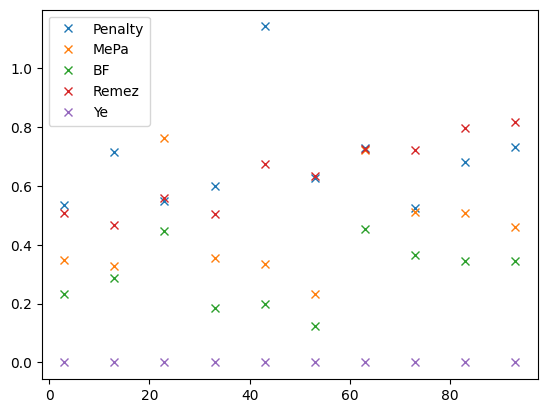

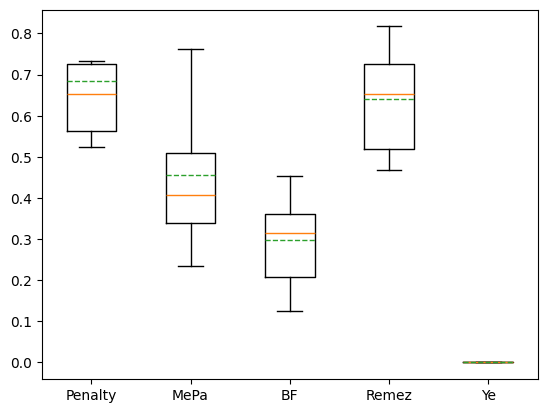

In [5]:
m=3
test(m,0,9)

In [ ]:
m=50
test(m,0,9)

In [14]:
#X,Y must be a box
Y=[(0,1)]
n=10
A=np.zeros((2*n+1,n+1))
b=np.ones((2*n+1))
for i in range(n):
        A[i][i]=-1
        A[n+i][i]=1
        A[-1][-1]=-1
        b[-1]=0
        
X=[(linear,[A,b])]
y0=[[np.random.rand()]]
x0=np.zeros(n+1)

def fcp(x):
    return x[-1]

def gcp(x,y):
    return -x[n]+cp.sum([(i*x[i-1]-i/n-np.sin(2*np.pi*y[0]+i))**2 for i in np.arange(1,n+1)])

def df(x):
    z=np.zeros(np.size(x))
    z[-1]=1
    return(z)

def dg(x,y):
    z=np.zeros(np.size(x))
    z[-1]=-1
    for i in np.arange(1,n+1):
        z[i-1]=2*i*(i*x[i-1]-i/n-np.sin(2*np.pi*y[0]+i))
    return(z)


def g(x,y):
    return -x[n]+sum([(i*x[i-1]-i/n-np.sin(2*np.pi*y[0]+i))**2 for i in np.arange(1,n+1)])

In [15]:

x0=np.zeros(n+1)
#res5=AlgCoM(x0,y0,fcp,gcp,g,df,dg,X,Y)

In [16]:

res1=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,drop_cuts=False)

Time 1.3846688270568848
Time upper problem 1.1677722930908203
Time lower problem 0.21689653396606445
Feasibility 0.0008800216362390145
Final rho 10
Rho increases 1
Optimal value 5.322892307943065
Value function call 9


In [8]:
res1=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,drop_cuts=True)

Time 1.9463527202606201
Time upper problem 1.7214810848236084
Time lower problem 0.22487163543701172
Feasibility -7.795404322052946e-08
Final rho 1
Rho increases 0
Optimal value 5.323256124747601
Value function call 16


In [17]:
res2=AlgMePa(x0,y0,fcp,gcp,g,X,Y,Ub=4*n)

Time 1.596381664276123
Time upper problem 1.3738155364990234
Time lower problem 0.2213764190673828
Feasibility 0.0008519339605195242
Optimal value 5.322892432086528
Optimality cuts 2
Feasibility cuts 8
Value function calls 10


In [18]:
res3=AlgBF(x0,y0,fcp,gcp,g,X,Y,drop_cuts=False)

Time 1.1012206077575684
Time upper problem 0.9008150100708008
Time lower problem 0.20040559768676758
Feasibility 0.0008800216362088165
Optimal value 5.3228923079430785
Value function call 8


In [11]:
res3=AlgBF(x0,y0,fcp,gcp,g,X,Y,drop_cuts=True)

Time 1.8934400081634521
Time upper problem 1.6345736980438232
Time lower problem 0.25773000717163086
Feasibility 1.1336209837509159e-07
Optimal value 5.323256001900975
Value function call 15


In [12]:
res4=AlgRemez(x0,y0,fcp,gcp,g,X,Y)

Time 9.431955099105835
Time upper problem 9.136651039123535
Time lower problem 0.2953040599822998
Feasibility 7.843616502967166e-07
Optimal value 5.323255510647762
Value function call 25


In [13]:
res4=AlgCoM(x0,y0,fcp,gcp,g,df,dg,X,Y)

Time 3.549457550048828
Time upper problem 1.54862380027771
Time lower problem 1.9799871444702148
Feasibility 9.406946584847217
Optimal value 0.049944102071703154
Value function call 99


In [5]:
print(res1[0])

[9.98919652e-03 1.00030998e-02 1.00000640e-02 1.00018838e-02
 9.99955827e-03 9.99924266e-03 9.99953842e-03 9.99960665e-03
 1.00009485e-02 9.99986629e-03 1.00007467e-02 9.99906159e-03
 1.00003822e-02 9.99916606e-03 1.00008602e-02 9.99961420e-03
 1.00007970e-02 9.99930795e-03 1.00003005e-02 9.99935112e-03
 1.00005239e-02 9.99984569e-03 1.00004916e-02 9.99969902e-03
 1.00000049e-02 9.99970276e-03 1.00001077e-02 1.00001581e-02
 1.00001254e-02 1.00000936e-02 9.99973568e-03 1.00000384e-02
 9.99976881e-03 1.00003338e-02 9.99986558e-03 1.00003218e-02
 9.99965602e-03 1.00001653e-02 9.99966008e-03 1.00003199e-02
 9.99986088e-03 1.00003121e-02 9.99974235e-03 1.00000834e-02
 9.99974901e-03 1.00001679e-02 9.99999385e-03 1.00001665e-02
 9.99993391e-03 9.99991777e-03 9.99992461e-03 9.99995490e-03
 1.00001511e-02 9.99998190e-03 1.00001318e-02 9.99979903e-03
 1.00000794e-02 9.99980320e-03 1.00002141e-02 9.99989497e-03
 1.00002143e-02 9.99979042e-03 1.00000910e-02 9.99979264e-03
 1.00001707e-02 9.999940

In [10]:
print(res2[0])

[0.09999932 0.09999819 0.09999766 0.10000034 0.10000085 0.10000112
 0.09999985 0.0999995  0.0999994  0.10000005 5.32325607]


In [9]:
np.arange(1,41)

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40])